In [1]:
# import the libraries
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn import metrics as m
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_recall_curve

In [2]:
# load data
from google.colab import drive
drive.mount('/content/drive/')


Mounted at /content/drive/


In [3]:
df = pd.read_csv("/content/drive/My Drive/bank.csv")
df

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33,blue-collar,single,primary,no,1,yes,no,cellular,20,apr,257,1,-1,0,unknown,no
11158,39,services,married,secondary,no,733,no,no,unknown,16,jun,83,4,-1,0,unknown,no
11159,32,technician,single,secondary,no,29,no,no,cellular,19,aug,156,2,-1,0,unknown,no
11160,43,technician,married,secondary,no,0,no,yes,cellular,8,may,9,2,172,5,failure,no


In [4]:
# choosing target variable
df.deposit = df.deposit.astype(str)
df.replace({'deposit': {'yes': 1, 'no': 0}},inplace=True)
y=df['deposit'].values

# choosing numeric features
df_log_reg = df[['age','balance','day','duration','campaign','pdays','previous']]




/tmp/ipykernel_3619/841815699.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.replace({'deposit': {'yes': 1, 'no': 0}},inplace=True)


In [5]:
df_log_reg

,age,balance,day,duration,campaign,pdays,previous
0,59,2343,5,1042,1,-1,0
1,56,45,5,1467,1,-1,0
2,41,1270,5,1389,1,-1,0
3,55,2476,5,579,1,-1,0
4,54,184,5,673,2,-1,0
...,...,...,...,...,...,...,...
11157,33,1,20,257,1,-1,0
11158,39,733,16,83,4,-1,0
11159,32,29,19,156,2,-1,0
11160,43,0,8,9,2,172,5


In [ ]:
df_log_reg

In [ ]:
y

In [6]:
# Create Train and Test samples
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(df_log_reg, y, test_size=0.3, random_state=42)


In [7]:
# !!! IMPORTANT !!!
# To avoid data information leakage you should train-test split first,
# fit the scaler on train data
# and transform train and test based on scaler parameters from the train

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [9]:
X_test

array([[ 2.00538946, -0.24652931, -1.25964156, ..., -0.55077471,
        -0.47257127, -0.37576201],
       [-0.27319069,  0.02805302,  0.04688368, ...,  2.38756793,
        -0.47257127, -0.37576201],
       [-0.52636626,  1.06543315, -0.19066637, ..., -0.55077471,
         2.31911811,  0.09262162],
       ...,
       [ 0.23316045,  0.12693998, -0.19066637, ..., -0.55077471,
        -0.47257127, -0.37576201],
       [ 1.16147089, -0.32085001,  0.1656587 , ..., -0.55077471,
         2.46751356,  0.09262162],
       [-0.52636626, -0.47788747,  0.52198376, ..., -0.55077471,
        -0.47257127, -0.37576201]])

In [ ]:
y_test.shape

In [10]:
# Log Regression
cls = LogisticRegression()
cls = cls.fit(X_train, y_train)

# Labels prediction
y_out = cls.predict(X_test)

# Probabilities for the objects in the test sample
y_out_proba = cls.predict_proba(X_test)

In [12]:
y_out_proba

array([[0.67771772, 0.32228228],
       [0.03501992, 0.96498008],
       [0.21003688, 0.78996312],
       ...,
       [0.68992161, 0.31007839],
       [0.64505756, 0.35494244],
       [0.024401  , 0.975599  ]])

In [13]:
y_out

array([0, 1, 1, ..., 0, 0, 1])

In [14]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(cls, X_test, y_test, cv=20)
scores

array([0.70238095, 0.69047619, 0.69642857, 0.75      , 0.73214286,
       0.75      , 0.7202381 , 0.73809524, 0.71428571, 0.80239521,
       0.80239521, 0.76646707, 0.79041916, 0.76646707, 0.76646707,
       0.67664671, 0.69461078, 0.71856287, 0.76646707, 0.81437126])

In [15]:
print(f"Cross val estimation for accuracy is {round(scores.mean(),3)} +/- {round(scores.std(),3)}")

Cross val estimation for accuracy is 0.743 +/- 0.04


In [16]:
# Metrics for binary classification

accuracy = m.accuracy_score(y_test,y_out)
precision = m.precision_score(y_test,y_out)
recall = m.recall_score(y_test,y_out)
roc_auc = roc_auc_score(y_out,y_test)
f1_score = m.f1_score(y_test,y_out)

In [17]:

print('accuracy', accuracy )
print('precision', precision )
print('recall', recall )
print('roc_auc', roc_auc )
print('F1-score', f1_score )

accuracy 0.7414153478650344
precision 0.7671232876712328
recall 0.6621032980709396
roc_auc 0.74518243894265
F1-score 0.7107548430193721


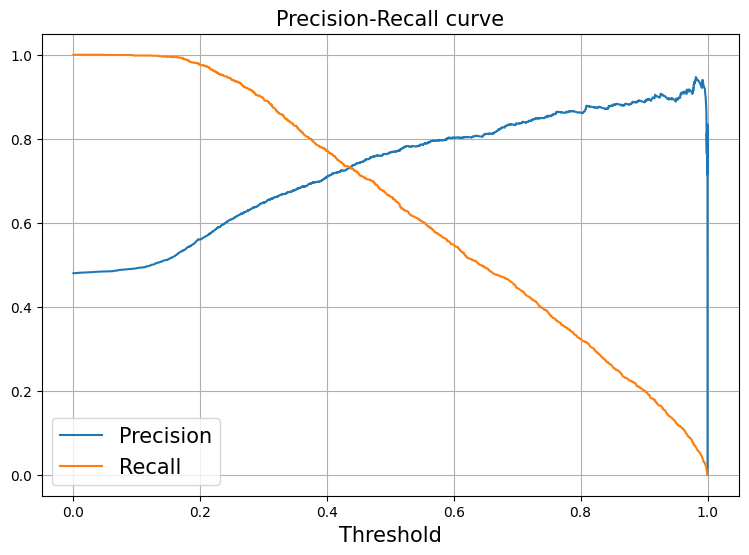

In [18]:

prec, rec, thresh = precision_recall_curve(y_test, y_out_proba[:,1])
plt.figure(figsize=(9, 6))
plt.grid()
plt.plot(thresh, prec[:-1], label="Precision")
plt.plot(thresh, rec[:-1], label="Recall")
plt.xlabel(u"Threshold",fontsize = 15)
plt.title(u'Precision-Recall curve',fontsize = 15)
plt.legend(fontsize = 15)

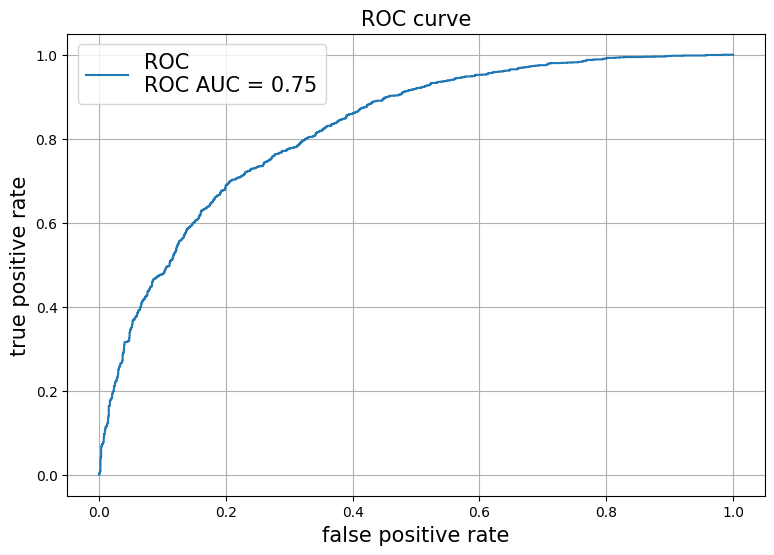

In [19]:
# ROC-curve
from sklearn.metrics import roc_curve, roc_auc_score
fpr, tpr, thr = roc_curve(y_test, y_out_proba[:,1])

plt.figure(figsize = (9,6))
plt.plot(fpr, tpr, label=u'ROC \n'+'ROC AUC = ' + str(round(roc_auc,2)))
plt.grid()
plt.xlabel("false positive rate",fontsize = 15)
plt.ylabel("true positive rate",fontsize = 15)
plt.title(u"ROC curve",fontsize = 15)
plt.legend(fontsize = 15)


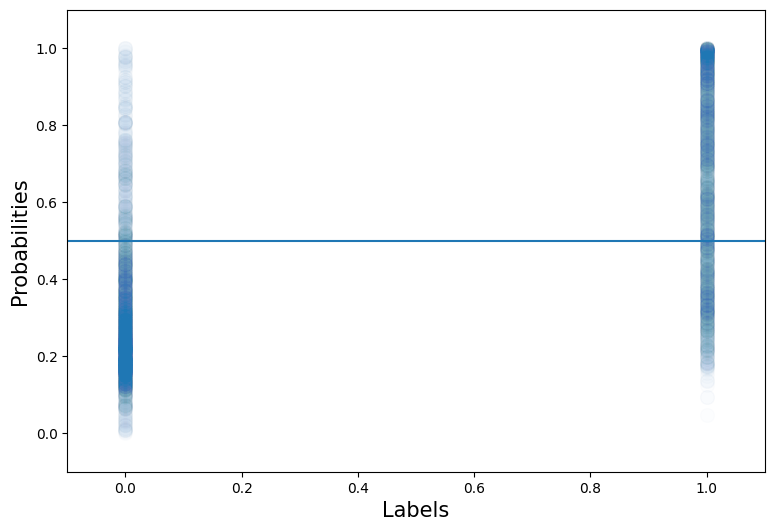

In [20]:
# predictions distribution
def scatter(actual, predicted, T):
    plt.figure(figsize = (9,6))
    plt.scatter(actual, predicted,s=100,alpha = 0.01)
    plt.xlabel(u"Labels",fontsize = 15)
    plt.ylabel(u"Probabilities",fontsize = 15)
    plt.plot([-0.2, 1.2], [T, T])
    plt.axis([-0.1, 1.1, -0.1, 1.1])
scatter(y_test,y_out_proba[:,1],0.5)